# Extended Data Figure 5: Action and assessment errors

The three rows compare instantaneous updating, full one-step inertia, and full selected multi-step inertia. Colors classify invasion by rare ALLD and ALLC in an all-DISC resident population. Run from this directory; set `RECOMPUTE=True` to generate the twelve 241-by-241 numerical grids.

## Configuration

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import json
import sys

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'extended_data_figure5'
FIGURES = ROOT / 'figures' / 'extended_data_figure5'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

B_OVER_C = 5.0
MAX_ERROR = 0.45
GRID_POINTS = 241
RELAX_DT = 0.18
RELAX_TOL = 1e-9
MAX_RELAX_STEPS = 120_000
INVASION_TOL = 1e-10
NORM_PARAMETERS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
SHORTEST_PAIRS = {'SC': (2, 0), 'SH': (3, 0), 'SJ': (4, 3), 'SS': (1, 2)}
NORM_ORDER = tuple(NORM_PARAMETERS)
CASE_ORDER = ('no_inertia', 'one_step_full', 'multistep_full')
CASE_NAMES = {'no_inertia': 'Without inertia', 'one_step_full': 'Full one-step inertia', 'multistep_full': 'Full multi-step inertia'}
CONFIG = dict(b_over_c=B_OVER_C, max_error=MAX_ERROR, grid_points=GRID_POINTS,
              relax_dt=RELAX_DT, relax_tolerance=RELAX_TOL,
              max_relax_steps=MAX_RELAX_STEPS, invasion_tolerance=INVASION_TOL,
              norms={key:list(value) for key,value in NORM_PARAMETERS.items()},
              multistep_depths={key:list(value) for key,value in SHORTEST_PAIRS.items()})
REGIME_CMAP = ListedColormap(['#D5A0A3', '#B3A4C7', '#80ADA5'])
REGIME_NORM = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], REGIME_CMAP.N)
COLOR_BOUNDARY = '#F2F0EA'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':9, 'axes.linewidth':.7,
                     'pdf.fonttype':42, 'svg.fonttype':'none'})


## Reputation and invasion calculations

Residents start at good reputation. Integration must satisfy the reputation residual criterion before a grid can be plotted. Categories use the stated numerical tolerances, with ALLD non-exclusion taking precedence.

In [2]:
def reputation_transform(phi, k1, k2, alpha=1.0, beta=1.0):
    """Stationary reputation map for the direct-reset inertia model."""
    phi, alpha, beta = np.broadcast_arrays(np.asarray(phi, float), np.asarray(alpha, float), np.asarray(beta, float))
    phi = np.clip(phi, 0.0, 1.0)
    one_minus = 1.0 - phi
    denominator = one_minus ** k1 + phi ** k2 - one_minus ** k1 * phi ** k2
    warning = np.zeros_like(phi)
    suspicious = np.zeros_like(phi)
    for m in range(1, k1 + 1):
        warning += (alpha * one_minus) ** m
    for n in range(1, k2 + 1):
        suspicious += phi ** n * (1.0 - beta ** n)
    numerator = phi ** (k2 + 1) * (1.0 + warning) + one_minus ** (k1 + 1) * suspicious
    return np.divide(numerator, denominator, out=np.zeros_like(numerator), where=np.abs(denominator) > 1e-15)

def effective_assessment(norm, e1, e2):
    """Positive-assessment probabilities conditional on intended action and recipient image."""
    p, q = NORM_PARAMETERS[norm]
    epsilon = (1.0 - e1) * (1.0 - e2) + e1 * e2
    p_cg = epsilon
    p_cb = p * (epsilon - e2) + q * (1.0 - epsilon - e2) + e2
    p_dg = e2
    p_db = q * (1.0 - 2.0 * e2) + e2
    return (p_cg, p_cb, p_dg, p_db)

def _resident_rhs(g, norm, k1, k2, e1, e2, alpha, beta):
    p_cg, p_cb, p_dg, p_db = effective_assessment(norm, e1, e2)
    phi_disc = g ** 2 * p_cg + g * (1.0 - g) * (p_cb + p_dg) + (1.0 - g) ** 2 * p_db
    return reputation_transform(phi_disc, k1, k2, alpha, beta) - g

def solve_all_good_branch(norm, k1, k2, e1, e2, alpha=1.0, beta=1.0):
    """Vectorized RK4 relaxation from g(0)=1 at every parameter point."""
    e1, e2, alpha, beta = np.broadcast_arrays(np.asarray(e1, float), np.asarray(e2, float), np.asarray(alpha, float), np.asarray(beta, float))
    shape = e1.shape
    e1f, e2f = (e1.ravel(), e2.ravel())
    af, bf = (alpha.ravel(), beta.ravel())
    g = np.ones_like(e1f)
    converged = np.zeros_like(g, dtype=bool)
    for _ in range(MAX_RELAX_STEPS):
        active = np.flatnonzero(~converged)
        if active.size == 0:
            break
        current = g[active]
        a1, a2 = (e1f[active], e2f[active])
        aa, bb = (af[active], bf[active])
        q1 = _resident_rhs(current, norm, k1, k2, a1, a2, aa, bb)
        newly = np.abs(q1) <= RELAX_TOL
        converged[active[newly]] = True
        moving = active[~newly]
        if moving.size == 0:
            continue
        current = g[moving]
        a1, a2 = (e1f[moving], e2f[moving])
        aa, bb = (af[moving], bf[moving])
        q1 = q1[~newly]
        q2 = _resident_rhs(np.clip(current + 0.5 * RELAX_DT * q1, 0, 1), norm, k1, k2, a1, a2, aa, bb)
        q3 = _resident_rhs(np.clip(current + 0.5 * RELAX_DT * q2, 0, 1), norm, k1, k2, a1, a2, aa, bb)
        q4 = _resident_rhs(np.clip(current + RELAX_DT * q3, 0, 1), norm, k1, k2, a1, a2, aa, bb)
        g[moving] = np.clip(current + RELAX_DT * (q1 + 2 * q2 + 2 * q3 + q4) / 6.0, 0.0, 1.0)
    residual = np.abs(_resident_rhs(g, norm, k1, k2, e1f, e2f, af, bf))
    converged = residual <= RELAX_TOL
    return (g.reshape(shape), converged.reshape(shape), residual.reshape(shape))

def invasion_result(norm, k1, k2, e1, e2, alpha=1.0, beta=1.0, b_over_c=B_OVER_C):
    e1, e2, alpha, beta, b_over_c = np.broadcast_arrays(np.asarray(e1, float), np.asarray(e2, float), np.asarray(alpha, float), np.asarray(beta, float), np.asarray(b_over_c, float))
    g, converged, residual = solve_all_good_branch(norm, k1, k2, e1, e2, alpha, beta)
    p_cg, p_cb, p_dg, p_db = effective_assessment(norm, e1, e2)
    phi_allc = g * p_cg + (1.0 - g) * p_cb
    phi_alld = g * p_dg + (1.0 - g) * p_db
    g_allc = reputation_transform(phi_allc, k1, k2, alpha, beta)
    g_alld = reputation_transform(phi_alld, k1, k2, alpha, beta)
    lambda_alld = (1.0 - e1) * (b_over_c * g_alld - (b_over_c - 1.0) * g)
    lambda_allc = (1.0 - e1) * (b_over_c * g_allc - 1.0 - (b_over_c - 1.0) * g)
    regime = np.full(g.shape, np.nan)
    regime[converged] = 2
    regime[converged & (lambda_allc > INVASION_TOL)] = 1
    regime[converged & (lambda_alld >= -INVASION_TOL)] = 0
    return {'g_DISC': g, 'g_ALLC': g_allc, 'g_ALLD': g_alld, 'lambda_ALLD': lambda_alld, 'lambda_ALLC': lambda_allc, 'regime': regime, 'converged': converged, 'residual': residual}

In [3]:
phi = np.linspace(0., 1., 101)
np.testing.assert_allclose(reputation_transform(phi, 0, 0, 0, 0), phi, rtol=0, atol=1e-14)
np.testing.assert_allclose(reputation_transform(phi, 1, 1, 0, 0), phi, rtol=0, atol=1e-14)
np.testing.assert_allclose(reputation_transform(phi, 1, 1, 1, 1),
                           phi**2 * (2-phi) / (1-phi+phi**2), rtol=0, atol=1e-14)
for k1,k2 in SHORTEST_PAIRS.values():
    np.testing.assert_allclose(reputation_transform([0.,1.],k1,k2), [0.,1.], atol=1e-14)
check = invasion_result('SC', 0, 0, .1, .1, alpha=0, beta=0)
epsilon = .9*.9 + .1*.1
np.testing.assert_allclose(check['g_DISC'], .1/(1-epsilon+.1), atol=2e-8, rtol=0)
assert bool(check['converged']) and float(check['residual']) <= RELAX_TOL
print('Model identity and resident-equilibrium checks passed.')


Model identity and resident-equilibrium checks passed.


## Numerical data

In [4]:
axis = np.linspace(0., MAX_ERROR, GRID_POINTS)
e1_grid, e2_grid = np.meshgrid(axis, axis, indexing='xy')
config_file = DATA / 'input_config.json'
if not RECOMPUTE:
    if not config_file.is_file():
        raise FileNotFoundError('Supply data/extended_data_figure5 or set RECOMPUTE=True.')
    if json.loads(config_file.read_text()) != CONFIG:
        raise ValueError('Saved grid settings do not match CONFIG. Set RECOMPUTE=True to regenerate.')

RESULTS = {}
start = perf_counter()
rows = []
for case in CASE_ORDER:
    for norm in NORM_ORDER:
        if case == 'no_inertia':
            k1,k2,alpha,beta = 0,0,0.,0.
        elif case == 'one_step_full':
            k1,k2,alpha,beta = 1,1,1.,1.
        else:
            k1,k2 = SHORTEST_PAIRS[norm]
            alpha = beta = 1.
        path = DATA / f'{case}_{norm}.npz'
        if RECOMPUTE:
            result = invasion_result(norm,k1,k2,e1_grid,e2_grid,alpha,beta)
            if not np.all(result['converged']):
                raise RuntimeError(f'{case}/{norm} contains unconverged resident points. No plot will be generated.')
            np.savez_compressed(path, e1_axis=axis, e2_axis=axis, **result)
        else:
            if not path.is_file():
                raise FileNotFoundError(f'Missing {path.name}; supply the data or set RECOMPUTE=True.')
            with np.load(path, allow_pickle=False) as saved:
                np.testing.assert_array_equal(saved['e1_axis'],axis)
                np.testing.assert_array_equal(saved['e2_axis'],axis)
                result={key:saved[key] for key in saved.files if key not in ('e1_axis','e2_axis')}
        assert all(value.shape==(GRID_POINTS,GRID_POINTS) for value in result.values())
        assert result['converged'].all() and result['residual'].max() <= RELAX_TOL
        assert np.isfinite(result['regime']).all()
        expected = np.full(result['regime'].shape,2.)
        expected[result['lambda_ALLC'] > INVASION_TOL] = 1
        expected[result['lambda_ALLD'] >= -INVASION_TOL] = 0
        np.testing.assert_array_equal(result['regime'],expected)
        RESULTS[case,norm]=result
        row=dict(case=case,norm=norm,k1=k1,k2=k2,alpha=alpha,beta=beta,
                 grid_points=GRID_POINTS**2,all_converged=bool(result['converged'].all()),
                 max_residual=float(result['residual'].max()))
        row.update({f'regime_{code}_count':int(np.sum(result['regime']==code)) for code in range(3)})
        rows.append(row)
        print(f'{case:16s} {norm}: max residual {row["max_residual"]:.2e}',flush=True)
if RECOMPUTE:
    config_file.write_text(json.dumps(CONFIG,indent=2)+'\n')
with (DATA/'grid_summary.csv').open('w',newline='') as stream:
    writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
metadata=dict(source_notebook='Fig3_e1_e2_error_shields_three_inertia_3x4.ipynb',
              equation='all-good scalar reputation relaxation; RK4',
              data_source='new computation' if RECOMPUTE else 'external numerical grids',
              python=sys.version.split()[0],numpy=np.__version__,configuration=CONFIG,
              total_grid_points=len(rows)*GRID_POINTS**2,
              categories={'0':'ALLD not excluded','1':'ALLD excluded; ALLC invades','2':'DISC resists both'},
              classification='ALLD non-exclusion takes precedence; finite numerical tolerances apply.')
(DATA/'metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
print(f'Prepared twelve grids ({perf_counter()-start:.1f} s).')


no_inertia       SC: max residual 1.00e-09


no_inertia       SH: max residual 1.00e-09


no_inertia       SJ: max residual 1.00e-09


no_inertia       SS: max residual 1.00e-09


one_step_full    SC: max residual 1.00e-09


...

multistep_full   SC: max residual 1.00e-09


multistep_full   SH: max residual 1.00e-09


multistep_full   SJ: max residual 1.00e-09


multistep_full   SS: max residual 1.00e-09


Prepared twelve grids (0.2 s).


## Panels and combined figure

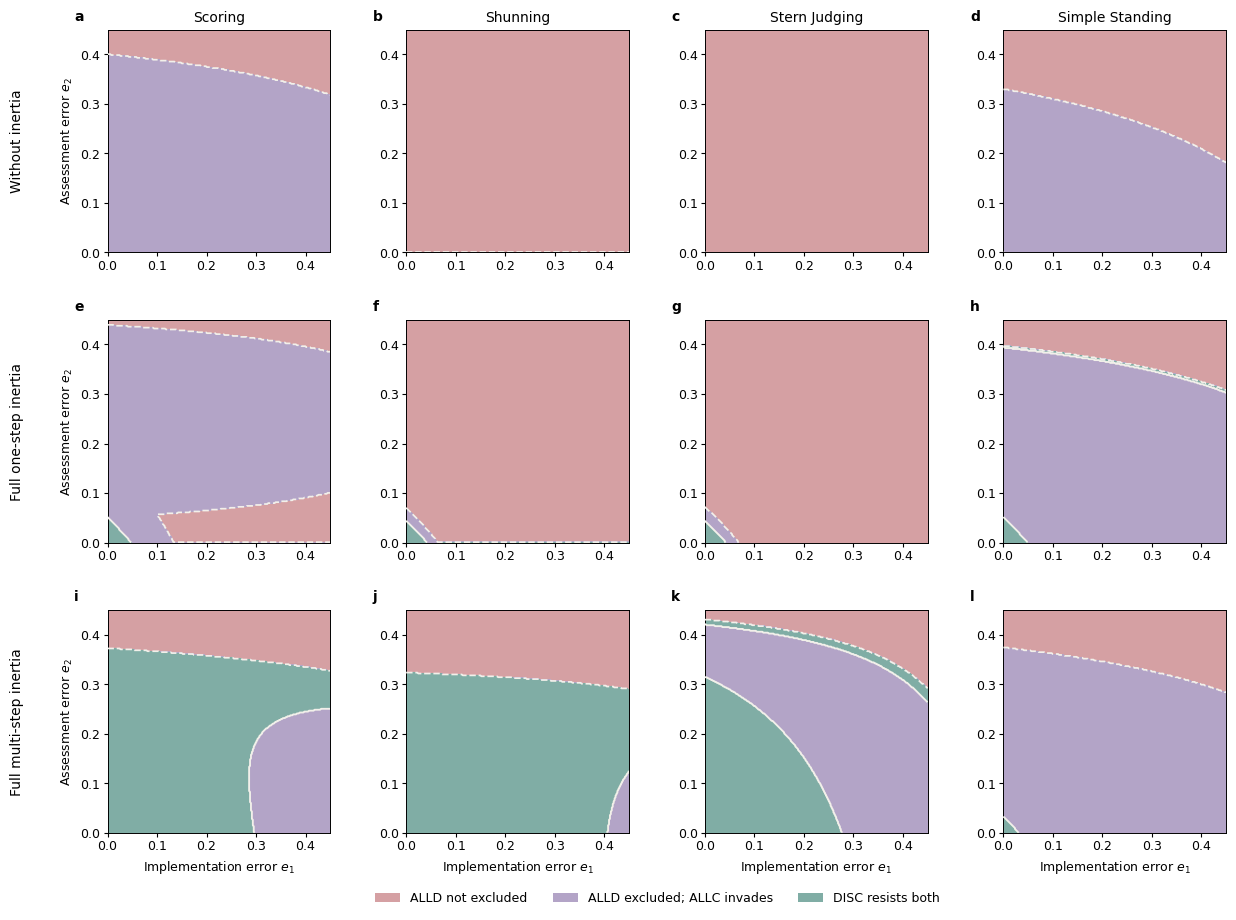

Saved twelve panels and one combined figure in PDF and SVG.


In [5]:
def draw_panel(ax,result):
    regime=result['regime']
    ax.contourf(e1_grid,e2_grid,regime,levels=[-.5,.5,1.5,2.5],
                cmap=REGIME_CMAP,norm=REGIME_NORM,antialiased=False)
    alld_region=(regime==0).astype(float)
    allc_region=np.ma.masked_where(regime==0,(regime==1).astype(float))
    for region,style,width in ((alld_region,'--',1.25),(allc_region,'-',1.35)):
        if region.min() < .5 < region.max():
            ax.contour(e1_grid,e2_grid,region,levels=[.5],colors=[COLOR_BOUNDARY],
                       linestyles=[style],linewidths=[width],zorder=7)
    ticks=np.arange(0.,.41,.1)
    ax.set(xlim=(0,MAX_ERROR),ylim=(0,MAX_ERROR),xticks=ticks,yticks=ticks,
           xlabel=r'Implementation error $e_1$',ylabel=r'Assessment error $e_2$',aspect='equal')
    ax.tick_params(length=3,pad=2)


def save_figure(fig,name):
    for extension in ('pdf','svg'):
        fig.savefig(FIGURES/f'{name}.{extension}',bbox_inches='tight',pad_inches=.04)

for case in CASE_ORDER:
    for norm in NORM_ORDER:
        fig,ax=plt.subplots(figsize=(3.6,3.45))
        draw_panel(ax,RESULTS[case,norm])
        ax.set_title(f'{NORM_NAMES[norm]}: {CASE_NAMES[case]}',fontsize=9)
        fig.tight_layout()
        save_figure(fig,f'{case}_{norm}')
        plt.close(fig)

fig,axes=plt.subplots(3,4,figsize=(12.5,9.8))
fig.subplots_adjust(left=.09,right=.985,bottom=.12,top=.94,wspace=.34,hspace=.30)
for row,case in enumerate(CASE_ORDER):
    for col,norm in enumerate(NORM_ORDER):
        ax=axes[row,col];draw_panel(ax,RESULTS[case,norm])
        if row==0:ax.set_title(NORM_NAMES[norm],fontsize=10)
        if col:ax.set_ylabel('')
        if row<2:ax.set_xlabel('')
        ax.text(-.15,1.04,'abcdefghijkl'[4*row+col],transform=ax.transAxes,
                fontweight='bold',fontsize=10)
    box=axes[row,0].get_position()
    fig.text(.012,(box.y0+box.y1)/2,CASE_NAMES[case],rotation=90,va='center',fontsize=10)
handles=[Patch(facecolor=REGIME_CMAP(code),edgecolor='none',label=label) for code,label in enumerate(
    ['ALLD not excluded','ALLD excluded; ALLC invades','DISC resists both'])]
fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.53,.035),ncol=3,frameon=False,fontsize=9)
save_figure(fig,'Extended_Data_Figure5_combined')
plt.show()
plt.close(fig)
expected=[f'{case}_{norm}' for case in CASE_ORDER for norm in NORM_ORDER]+['Extended_Data_Figure5_combined']
assert all((FIGURES/f'{name}.{extension}').is_file() for name in expected for extension in ('pdf','svg'))
print('Saved twelve panels and one combined figure in PDF and SVG.')
